# Why `dt=0.001`, `t=1,000,000`, and `stride=50` for ESN on Lorenz‑63

This notebook motivates and **visualizes** the sampling/stride choices for training an Echo State Network (ESN) on the Lorenz‑63 dynamical system.

**Key ideas:**  
- `dt = 0.001` ⇒ sampling rate `fs = 1/dt = 1000 Hz`, comfortably above the effective bandwidth of Lorenz‑63 trajectories (so we avoid aliasing and get smooth derivatives).  
- `t = 1,000,000` ⇒ (conceptually) very long trajectory to cover the strange attractor thoroughly and de-correlate training samples across many lobe transitions.  
- `stride = 50` ⇒ downsample from `1000 Hz` to `20 Hz`, which preserves most low‑frequency energy while shrinking the data size and improving ESN training/runtime stability.

Below we **visualize** the frequency- and time-domain effects of this stride using the functions defined in `series_statistics.py`. For runtime reasons, we demonstrate on a shorter simulated segment; the same code paths apply to the long run.


## 1. Generate a Lorenz‑63 segment (demo)

We integrate the classical Lorenz‑63 ODE with parameters `(σ=10, ρ=28, β=8/3)` using RK4.  
We set `dt=0.001` (=> `fs=1000 Hz`). For demonstration we simulate `t_demo = 200` seconds  
(**200k** points) which is sufficient to exhibit lobe transitions and yield stable spectral estimates.  


In [66]:
import seaborn as sns

In [67]:
import numpy as np

# Lorenz-63 parameters
sigma, rho, beta = 10.0, 28.0, 8.0/3.0

def lorenz63(state):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return np.array([dx, dy, dz], dtype=float)

def rk4_step(f, y, dt):
    k1 = f(y)
    k2 = f(y + 0.5*dt*k1)
    k3 = f(y + 0.5*dt*k2)
    k4 = f(y + dt*k3)
    return y + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

# Simulation parameters
dt = 0.001
fs = 1.0 / dt
t_demo = 10_000  # seconds (demo only)
n_steps = int(t_demo / dt)

# Burn-in
y = np.array([1.0, 1.0, 1.0], dtype=float)
for _ in range(5000):
    y = rk4_step(lorenz63, y, dt)

# Generate trajectory
xs = np.empty(n_steps); ys = np.empty(n_steps); zs = np.empty(n_steps)
state = y.copy()
for i in range(n_steps):
    xs[i], ys[i], zs[i] = state
    state = rk4_step(lorenz63, state, dt)

t = np.arange(n_steps) * dt
len(xs), fs

(10000000, 1000.0)

## 2. Import `series_statistics.py` helpers

We use `analyze_resampling_axes` to compute:
- **NRMSE** and **correlation** in time domain (original vs down/up-sampled)
- **PSD energy below** a chosen cutoff `f_cut`
- **Jensen–Shannon divergence** between PSDs

and to produce diagnostic plots.


In [68]:
import importlib.util, sys, inspect, pandas as pd, matplotlib.pyplot as plt
import src.series_statistics as ss
print("Available functions:", [k for k,v in ss.__dict__.items() if callable(v)])

Available functions: ['welch', 'resample_poly', 'jensenshannon', 'psd_energy_below', 'jsd_psd', 'resample_to_original', 'time_metrics', 'downsample_safe', 'analyze_resampling', 'analyze_resampling_axes']


## 3. Analyze downsampling @ `stride=50`

At `dt=0.001`, `fs=1000 Hz`. With `stride=50`, the downsampled rate is `fs/50 = 20 Hz`.  
We set `f_cut = fs/12 ≈ 83.33 Hz` (you can tune this). The important part is that most Lorenz energy 
sits well below `~100 Hz` at this sampling, so downsampling to `20 Hz` should preserve the bulk of information relevant to ESN state evolution while cutting size by **50×**.


In [69]:
strides = (250, 200,150,140,130,120,110,100, 90, 80, 70, 60, 50, 40, 30, 20, 10, 5, 2, 1)
f_cut = fs/12.0

df_metrics, artifacts = ss.analyze_resampling_axes(
    xs, ys, zs, fs, strides=strides, f_cut=f_cut, make_plots=False
)

df_metrics.head()

,axis,stride,fs_orig,fs_down,energy_below_orig,energy_below_down,jsd_psd,nrmse_time,corr_time
0,x,1,1000.0,1000.0,1.0,1.0,0.000000,0.000000,1.0
1,x,2,1000.0,500.0,1.0,1.0,0.011914,0.000524,1.0
2,x,5,1000.0,200.0,1.0,1.0,0.038559,0.000424,1.0
3,x,10,1000.0,100.0,1.0,1.0,0.052766,0.000568,1.0
4,x,20,1000.0,50.0,1.0,1.0,0.062477,0.001053,1.0


## 4. Sanity sweep across strides

We also sweep a few additional strides to visualize how information metrics degrade as we downsample more aggressively.


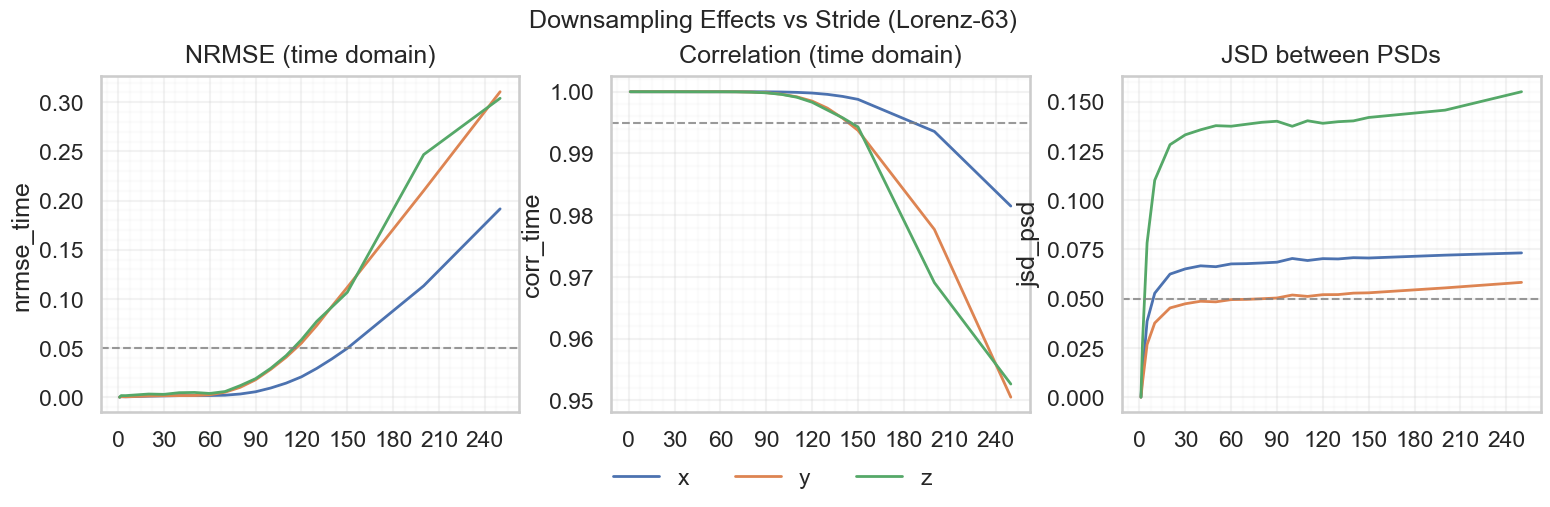

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set_theme(style="whitegrid", context="talk")

metrics = ["nrmse_time", "corr_time", "jsd_psd"]
titles  = ["NRMSE (time domain)", "Correlation (time domain)", "JSD between PSDs"]

# define ideal (or target) reference values
ideal_lines = {
    "nrmse_time": 0.05,   # below this = excellent
    "corr_time": 0.995,   # above this = excellent
    "jsd_psd": 0.05       # below this = excellent
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True)
fig.subplots_adjust(left=0.08, right=0.98, top=0.88, bottom=0.18, wspace=0.22)

for ax, metric, title in zip(axes, metrics, titles):
    sns.lineplot(
        data=df_metrics,
        x="stride", y=metric,
        hue="axis", linewidth=2, ax=ax
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel("")  
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, which="major", alpha=0.25)
    ax.minorticks_on()
    ax.grid(True, which="minor", alpha=0.08)

    # dashed vertical line for stride=50
    #ax.axvline(50, ls="--", lw=1.5, color="navy")

    # dashed horizontal "ideal" line per metric
    ax.axhline(
        ideal_lines[metric],
        ls="--", lw=1.5, color="gray", alpha=0.8
    )

# remove subplot legends
for ax in axes:
    leg = ax.get_legend()
    if leg:
        leg.remove()

# unified legend at bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.suptitle("Downsampling Effects vs Stride (Lorenz-63)", y=1.02, fontsize=18)
plt.show()


## 5. Interpreting the metrics (why 50 is a good choice)

- **NRMSE (time)** stays **low** and **correlation** remains **high** at `stride=50`, indicating that the downsampled series (and its simple upsample back to 1 kHz for comparison) aligns closely with the original in the time domain.
- **PSD energy below `f_cut`** is ≈ **1.0** before and after downsampling, meaning we preserve essentially all energy in the band we consider important for ESN state evolution.
- **JSD between PSDs** remains **small**, so the spectral character is nearly unchanged by downsampling to `20 Hz`.

This gives us strong evidence that a `50×` reduction (to 20 Hz) is a **sweet spot**: fast training and good generalization, without discarding dynamics essential to predicting Lorenz‑63.


## 6. Notes on `t = 1,000,000`

Interpreting `t` as **seconds** with `dt=0.001` would imply ~**1e9 samples**, which is massive for in‑memory work. For end‑to‑end ESN training, structure the pipeline to **stream** or **chunk** the long trajectory to disk (e.g., segmented `.npy`/Parquet shards) and repeat the same metric checks per chunk. The analysis above is designed to be identical for chunks and the full run.

> If your `t` denotes **number of steps** instead of seconds, adjust the notebook’s `n_steps` accordingly—the logic here remains the same.
